# ПЗ-3. Исследование языковых моделей: prompt, данные и оценка

В этой практической работе рассмотрим использование готовой языковой модели для обработки новостных текстов. На примере задачи автоматического реферирования последовательно разберем, как формулировка запроса, состав примеров и качество входных данных влияют на результат:
- вызов готовой языковой модели и построение prompt;
- zero-shot, one-shot и few-shot prompting;
- структурированный вывод в формате JSON и извлечение информации из новостей;
- автоматическая оценка резюме с помощью BLEU и ROUGE;
- сравнение вариантов prompt на выборке новостей и выбор лучшего варианта.

Главная цель практики: понять, как составление prompt влияет на поведение готовой языковой модели, почему качество нужно оценивать на выборке и как фиксировать prompt и результаты экспериментов.

**Выполнил:** Бабушкин Михаил Вадимович, ЕТ-228, 2026.


## Подготовка

Ноутбук использует локальную GGUF-модель через `llama-cpp-python`. Датасеты загружаются из Hugging Face, эксперименты сохраняются в локальном MLflow. В демонстрационном запуске используются 100 новостей.
Ячейка установки ниже рассчитана **только на Google Colab**. Она ставит сборку `llama-cpp-python` с поддержкой CUDA 12.4 и подгружает библиотеки CUDA по путям, которые существуют только в окружении Colab (`/usr/local/lib/python*/dist-packages`). Поэтому при локальном запуске ее выполнять не нужно, а подготовку окружения следует сделать вручную.
Для NVIDIA вместо сборки можно взять готовую сборку: `pip install llama-cpp-python --extra-index-url https://abetlen.github.io/llama-cpp-python/whl/cu124`.
Проверьте, что ускорение на GPU доступно:

```python
from llama_cpp import llama_supports_gpu_offload
print(llama_supports_gpu_offload())
```

Если результат `False`, а видеокарта есть, библиотеки CUDA не найдены: проверьте установку CUDA и переменную `LD_LIBRARY_PATH`.
Если GPU нет, в ячейках подключения моделей замените `n_gpu_layers=-1` на `n_gpu_layers=0` и уменьшите `N_EVAL`: на CPU генерация заметно медленнее.


**Локальный запуск:** macOS arm64, Python 3.12, `llama-cpp-python` с Metal. Ячейка установки для Colab пропущена; используется окружение `.venv` репозитория.


In [1]:
# Ячейка предназначена для Colab; при локальном запуске не выполняется.
# %pip install -q datasets huggingface_hub mlflow nltk rouge-score pandas matplotlib tqdm
#
# %pip uninstall -y llama-cpp-python
#
# %pip install -q --no-cache-dir \
#   nvidia-cuda-runtime-cu12 \
#   nvidia-cublas-cu12
#
# %pip install -q --no-cache-dir \
#   llama-cpp-python \
#   --extra-index-url https://abetlen.github.io/llama-cpp-python/whl/cu124
#
# import glob
# import ctypes
#
# names = [
#     "libcudart.so.12",
#     "libcublas.so.12",
#     "libcublasLt.so.12",
# ]
#
# for name in names:
#     files = glob.glob(
#         f"/usr/local/lib/python*/dist-packages/nvidia/**/{name}",
#         recursive=True,
#     )
#     if files:
#         ctypes.CDLL(files[0], mode=ctypes.RTLD_GLOBAL)
#
# from llama_cpp import llama_supports_gpu_offload
#
# print("GPU offload support:", llama_supports_gpu_offload())

Если результаты должны сохраниться после остановки Colab, перед ячейкой MLflow можно подключить Google Drive. Это необязательно для работы примеров:

```python
# from google.colab import drive
# drive.mount("/content/drive")
# os.makedirs("/content/drive/MyDrive/pz3_llm", exist_ok=True)
# os.chdir("/content/drive/MyDrive/pz3_llm")
```

### Параметры эксперимента

Перед загрузкой модели зададим константы, которые будут использоваться во всех дальнейших экспериментах. Они одинаковы для всех вариантов prompt и всех наборов данных, поэтому различия в метриках объясняются именно изменением prompt или данных, а не настроек. Часть значений записывается в MLflow как параметры запуска.

- **`SEED`** - начальное значение генератора случайных чисел.
- **`MODEL_REPO`** - репозиторий на Hugging Face, из которого загружается модель.
- **`MODEL_FILENAME`** - конкретный файл в репозитории. В названии `Qwen3-8B-Q4_K_M` закодированы две характеристики: `8B` - около 8 миллиардов параметров, а `Q4_K_M` - квантование весов до 4 бит. Квантование сжимает модель, и она занимает значительно меньше памяти, чем при хранении весов в 16 битах; качество при этом снижается незначительно. `.gguf` - формат файла, в котором модель запускается через `llama-cpp-python`. В одном файле хранятся веса, а также настройки архитектуры и токенизатор, поэтому отдельные файлы конфигурации и токенизатора, как в ПЗ-2, не нужны.
- **`TEXT_CHAR_LIMIT`** - сколько первых символов статьи получает модель. Ограничение сокращает длину prompt и время генерации. Если важная информация находится дальше границы, модель ее не увидит.
- **`EXAMPLE_CHAR_LIMIT`** - аналогичное ограничение для текстов примеров в one-shot и few-shot prompt. Примеры занимают место в контекстном окне модели, поэтому их сокращают сильнее, чем оцениваемую новость. Обрезка может убрать из примера факты, которые упомянуты в его резюме.
- **`MAX_TOKENS`** - максимальная длина ответа модели в токенах.

| Модель | Параметров | `MODEL_REPO` | `MODEL_FILENAME` | Размер файла, ГБ | Когда использовать |
|---|---|---|---|---|---|
| Qwen3-1.7B | 1,7 млрд | `bartowski/Qwen_Qwen3-1.7B-GGUF` | `Qwen_Qwen3-1.7B-Q4_K_M.gguf` | около 1,3 | быстрая проверка кода, слабая видеокарта или CPU; качество резюме низкое |
| Qwen3-4B | 4 млрд | `Qwen/Qwen3-4B-GGUF` | `Qwen3-4B-Q4_K_M.gguf` | 2,5 | быстрее базового варианта |
| Qwen3-8B | 8 млрд | `Qwen/Qwen3-8B-GGUF` | `Qwen3-8B-Q4_K_M.gguf` | 5,0 | базовый вариант работы |

In [2]:
import json
import os
import random
import re
import time
from collections import Counter
from itertools import islice
from pathlib import Path

CACHE_DIR = Path(".cache").resolve()
CACHE_DIR.mkdir(exist_ok=True)
os.environ["HF_HOME"] = str(CACHE_DIR / "huggingface")
os.environ["MPLCONFIGDIR"] = str(CACHE_DIR / "matplotlib")

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
from datasets import load_dataset
from nltk.translate.bleu_score import SmoothingFunction, sentence_bleu
from rouge_score import rouge_scorer
from tqdm.auto import tqdm

SEED = 42
MODEL_REPO = "Qwen/Qwen3-8B-GGUF"
MODEL_FILENAME = "Qwen3-8B-Q4_K_M.gguf"
TEXT_CHAR_LIMIT = 3000
EXAMPLE_CHAR_LIMIT = 700
MAX_TOKENS = 256

random.seed(SEED)
np.random.seed(SEED)

Matplotlib is building the font cache; this may take a moment.


/Users/mikhail/Developer/2026-autumn/NNTSM-2026/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026/10/31 18:30:40 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /Users/mikhail/Developer/2026-autumn/NNTSM-2026/.venv/lib/python3.12/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


### Подключение модели

Языковую модель можно получить двумя способами:

- **запустить локально**: модель загружается в память, данные никуда не передаются, но для работы нужны ресурсы видеокарты;
- **обращаться к серверу по API**: модель работает на стороне провайдера (облачный сервис) или на отдельном сервере, который вы запустили сами (например, `llama.cpp server`, Ollama, vLLM). Локальной видеокарты при этом не требуется, но запросы уходят на сервер, у облачных сервисов они могут быть платными, а скорость зависит от нагрузки и ограничений провайдера.

В этой работе используется первый вариант: модель загружается из GGUF-репозитория и запускается локально. Весь остальной ноутбук обращается к модели только через функцию `ask_llm`.

Параметры загрузки модели:

- **`n_ctx`** - размер контекстного окна в токенах. Prompt вместе с ответом должен в него помещаться. Увеличение окна требует дополнительной памяти.
- **`n_gpu_layers`** - сколько слоев модели выполняется на видеокарте. Значение `-1` означает все слои, значение `0` - вычисления только на CPU.

Параметры вызова модели:

- **`messages`** - запрос в виде списка сообщений. Каждое сообщение имеет роль (`user`, `system`, `assistant`) и текст. В работе используется одно сообщение от пользователя, в котором находятся инструкция и исходные данные.
- **`temperature=0`** - выбор наиболее вероятного токена на каждом шаге, как в greedy-генерации из ПЗ-2. Ответ становится стабильным, и различия в метриках объясняются изменением prompt или данных, а не случайностью.
- **`max_tokens`** - предельная длина ответа в токенах.
- **`/no_think`** - служебная метка Qwen3, которая отключает режим рассуждений. Для моделей других семейств она не нужна и должна быть удалена из запроса.

In [3]:
from llama_cpp import Llama

LLM = Llama.from_pretrained(
    repo_id=MODEL_REPO,
    filename=MODEL_FILENAME,
    n_ctx=8192,
    n_gpu_layers=-1,
    seed=SEED,
    verbose=False,
)

def ask_llm(prompt: str, temperature: float = 0.0, max_tokens: int = MAX_TOKENS) -> str:
    """Отправляет prompt локальной модели.

    Args:
        prompt: Инструкция и исходные данные.
        temperature: Степень случайности генерации.
        max_tokens: Максимальная длина ответа в токенах.

    Returns:
        Текст ответа модели.
    """
    response = LLM.create_chat_completion(
        messages=[{"role": "user", "content": f"{prompt}\n/no_think"}],
        temperature=temperature,
        max_tokens=max_tokens,
    )
    answer = response["choices"][0]["message"]["content"] or ""
    answer = re.sub(r"<think>.*?</think>", "", answer, flags=re.DOTALL)
    answer = re.sub(r"<think>.*", "", answer, flags=re.DOTALL)
    return answer.strip()

print("Локальная модель загружена")

/Users/mikhail/Developer/2026-autumn/NNTSM-2026/.venv/lib/python3.12/site-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


llama_context: n_ctx_seq (8192) < n_ctx_train (40960) -- the full capacity of the model will not be utilized


Локальная модель загружена


## 1. Первый prompt

В ПЗ-2 мы обучали собственную модель, и результат определяли ее архитектура и данные обучения. Теперь модель готова и не меняется, а изменять мы будем только то, что ей отправляем. **Prompt** - это текст запроса: инструкция вместе с исходными данными. Одна и та же модель на одну и ту же новость может дать разные ответы в зависимости от того, как сформулирована инструкция. В этом разделе мы посмотрим на эту зависимость на одной новости.

### Данные

Используем `IlyaGusev/gazeta` - корпус русскоязычных новостей с резюме. В каждой записи два поля:

- `text` - текст статьи;
- `summary` - эталонное резюме, написанное человеком.


Модель получает только первые `TEXT_CHAR_LIMIT` символов статьи. Ограничение сокращает prompt и время генерации и одинаково для всех экспериментов, поэтому не влияет на сравнение вариантов. Но если важная информация находится в обрезанной части, модель ее не увидит, и оценка может снизиться.

In [4]:
def load_news(split: str, limit: int) -> list[dict]:
    """Загружает статьи с непустыми текстом и резюме.

    Args:
        split: Название части датасета Gazeta.
        limit: Максимальное число новостей.

    Returns:
        Список записей датасета.
    """
    dataset = load_dataset("IlyaGusev/gazeta", split=split, streaming=True)
    return list(islice((item for item in dataset if (item.get("text") or "").strip() and (item.get("summary") or "").strip()), limit))

N_EVAL = 100
evaluation_news = load_news("test", N_EVAL)
examples = load_news("train", 10)
row = evaluation_news[0]
news = row["text"][:TEXT_CHAR_LIMIT]
print("Новость:\n", news[:800], "...")
print("\nЭталон:\n", row["summary"])

Новость:
 На этих выходных в Берлине прошли крупные акции протеста против введенных для борьбы с коронавирусом ограничений. Демонстранты скандировали «Путин!» По словам депутата городской палаты представителей Гуннара Линдеманна («Альтернатива для Германии»), люди выкрикивали фамилию российского президента из уважения к нему. В комментарии РИА «Новости» немецкий политик отметил, что среди населения Германии Владимир Путин имеет хорошую репутацию. По его мнению, протестующие ранее пришли к российскому посольству, чтобы «привлечь внимание к условиям в Германии», надеясь, что Россия сможет оказать влияние на канцлера ФРГ Ангелу Меркель. «На мой взгляд, опасности для посольства России не возникло ни разу», — сказал депутат. Несмотря на то что протест оказался массовым, выступления носили «преимущественн ...

Эталон:
 Протестующие против антикоронавирусных мер немцы скандировали имя российского президента, потому что уважают его. Такое мнение выразил депутат городской палаты представителей 

### Простая инструкция

Начнем с самого короткого запроса. Prompt здесь состоит из двух частей: **инструкции** («Сделай краткое содержание новости») и **исходных данных** (текст новости). Данные отделены от инструкции пустой строкой и подписью `Новость:`, чтобы модель могла отличить, где задание, а где материал для работы. В коде prompt собирается f-строкой: вместо `{news}` подставляется текст статьи, обрезанный до `TEXT_CHAR_LIMIT` символов.

Запустите ячейку и сравните ответ модели с эталонным резюме, которое было выведено выше. Обратите внимание на следующее:

- длина ответа: сколько в нем предложений и совпадает ли это с эталоном;
- содержание: какие факты модель передала, какие пропустила, не добавила ли лишнего;
- оформление: нет ли в ответе вступлений вроде «Вот краткое содержание», списков или заголовков;
- повторяемость: при `temperature=0` повторный запуск ячейки дает тот же ответ, поэтому различия между запусками возможны только после изменения prompt.

Инструкция не задает ни длину, ни формат, ни требований к фактам, поэтому модель выбирает все это сама. В следующей ячейке мы зададим их явно.

In [5]:
prompt = f"Сделай краткое содержание новости.\n\nНовость:\n{news}"
prediction = ask_llm(prompt)
print("Ответ модели:\n", prediction)

Ответ модели:
 В Берлине прошли массовые акции протеста против антиковидных ограничений, включая ношение масок и соблюдение социального дистанции. Протестующие скандировали «Путин!», выражая уважение к российскому президенту. По словам депутата Гуннара Линдеманна, протесты были в основном мирными, хотя в районе российского посольства произошли стычки с полицией. Участники манифестаций бросали камни и бутылки, но, по словам полиции, действия не были направлены против дипломатической миссии. Всего в акциях участвовало около 18 тысяч человек.


### Уточняем задачу

Первая инструкция не задавала ни длину, ни формат, ни требований к фактам, поэтому модель выбирала все это сама. Теперь зададим их явно. В новый prompt добавлены три элемента:

- **Роль** («Ты редактор новостей»). Она подсказывает модели, в каком стиле и с какой целью писать ответ.
- **Формат и длина** («нейтральное резюме в 1–2 предложениях»). Это ограничивает объем и тон ответа.
- **Ограничение на содержание** («не добавляй фактов, которых нет в исходном тексте»). Языковая модель может дополнить текст сведениями, которых в нем нет, и эта фраза направлена против такого поведения.

Структура prompt тоже изменилась. Инструкция идет перед новостью, а в конце стоит слово `Резюме:`. Оно показывает, с чего должен начаться ответ, и помогает модели сразу перейти к резюме без вступления.

In [6]:
prompt = f"""Ты редактор новостей.
Сделай нейтральное резюме новости в 1–2 предложениях.
Не добавляй фактов, которых нет в исходном тексте.

Новость:
{news}

Резюме:"""
prediction = ask_llm(prompt)
print("Ответ модели:\n", prediction)

Ответ модели:
 В Берлине прошли массовые акции протеста против антикоронавирусных ограничений, в ходе которых участники скандировали имя российского президента. Полиция отреагировала на столкновения, но не сообщила о серьезных инцидентах.


### Структурированный ответ

До сих пор ответ модели читал человек, и формат не имел значения. Если результат должна обработать программа (записать в таблицу, подсчитать, передать дальше), текст в свободной форме не подходит: из него неудобно извлекать значения. В таких случаях просят ответ в **структурированном формате**, чаще всего в JSON: набор пар «поле: значение», который можно разобрать стандартной функцией.

В prompt для этого задаются:

- **формат** («верни только JSON»): слово «только» просит не добавлять пояснений и вступлений, которые нарушили бы структуру;
- **поля** (`event` и `summary`): названия ключей, которые мы ожидаем получить, и что должно лежать в каждом из них. Здесь `event` - короткое название события, а `summary` - резюме в 1–2 предложениях;
- **ограничение на содержание** («не добавляй фактов, которых нет в исходном тексте»): то же, что и в предыдущей ячейке.

В конце prompt стоит слово `JSON` : так же, как `Резюме:` в предыдущей ячейке, оно показывает, с чего должен начаться ответ.

Код разбирает ответ функцией `json.loads`. Просьба вернуть JSON не гарантирует корректного результата: модель может добавить пояснение, обернуть ответ в блок кода с обратными кавычками, пропустить кавычку или запятую. Поэтому разбор выполняется внутри `try/except`, и неудачу нужно обработать, а не считать, что ответ всегда корректен.


In [7]:
json_prompt = f"""Прочитай новость и верни только JSON с полями event и summary.
event: короткое название события, о котором новость (одна фраза).
summary: резюме новости в 1–2 предложениях.
Не добавляй фактов, которых нет в исходном тексте.

Новость:
{news}

JSON:"""
json_prediction = ask_llm(json_prompt)
print("Ответ модели:\n", json_prediction)
try:
    print("\nРазобранный JSON:", json.loads(json_prediction))
except json.JSONDecodeError:
    print("\nОтвет не удалось разобрать как JSON.")

Ответ модели:
 {
  "event": "Массовые акции протеста в Берлине против антикоронавирусных мер",
  "summary": "В Берлине прошли протесты против ограничений, связанных с борьбой с коронавирусом, с участием около 18 тысяч человек. Протестующие скандировали фамилию российского президента и вступали в конфликт с полицией."
}

Разобранный JSON: {'event': 'Массовые акции протеста в Берлине против антикоронавирусных мер', 'summary': 'В Берлине прошли протесты против ограничений, связанных с борьбой с коронавирусом, с участием около 18 тысяч человек. Протестующие скандировали фамилию российского президента и вступали в конфликт с полицией.'}


### Задание 1: города в новостях

Предыдущая ячейка показала, как получить от модели структурированный ответ для одной новости. Теперь применим тот же прием к 100 новостям и посмотрим, как ведет себя результат на выборке.

**Задание.** Постройте распределение городов в новостях по ответам модели.

1. Возьмите первые 100 новостей из тестовой части.
2. Для каждой новости составьте prompt, по которому модель вернет JSON с одним полем `city`. Задайте правило для случая, когда город в новости не указан.
3. Разберите ответ и отнесите каждую новость к одной из трех категорий:
   - название города;
   - `Не указан` (модель вернула `null` или пустое значение);
   - `Ошибка JSON` (ответ не удалось разобрать).
4. Посчитайте число новостей в каждой категории (`Counter`) и постройте круговую диаграмму.


Города:   0%|          | 0/100 [00:00<?, ?it/s]

Города:   6%|▌         | 6/100 [00:11<02:57,  1.88s/it]

Города:   6%|▌         | 6/100 [00:22<02:57,  1.88s/it]

Города:  12%|█▏        | 12/100 [00:24<02:58,  2.02s/it]

Города:  18%|█▊        | 18/100 [00:35<02:43,  2.00s/it]

...

Города:  90%|█████████ | 90/100 [04:22<00:34,  3.44s/it]

Города:  94%|█████████▍| 94/100 [04:24<00:20,  3.34s/it]

Города:  98%|█████████▊| 98/100 [04:36<00:06,  3.25s/it]

Города: 100%|██████████| 100/100 [04:42<00:00,  2.82s/it]

Обработано новостей: 100
Counter({'Не указан': 43, 'Москва': 8, 'Минск': 7, 'Санкт-Петербург': 3, 'Портленд': 2, 'Одесса': 2, 'Берлин': 1, 'Абу-Даби': 1, 'Эстония': 1, 'Бухарск': 1, 'Крым': 1, 'Екатеринбург': 1, 'Борнхольм': 1, 'Лилль': 1, 'Аляска': 1, 'Саранск': 1, 'Велюнь': 1, 'Пассау': 1, 'Воскресенск': 1, 'Флорида': 1, 'Бугульма': 1, 'Андерсон': 1, 'Кигинский район': 1, 'Массачусетс': 1, 'Майами-Бич': 1, 'Лас-Вегас': 1, 'Вервье': 1, 'Вашингтон': 1, 'Фрайдей Харбор': 1, 'Приморск': 1, 'Казань': 1, 'Мальта': 1, 'Париж': 1, 'Мельбурн': 1, 'Калининград': 1, 'Красноярск': 1, 'Пекин': 1, 'Форт-Ворче': 1, 'Готланд': 1, 'Чаншэ': 1, 'Триполи': 1})


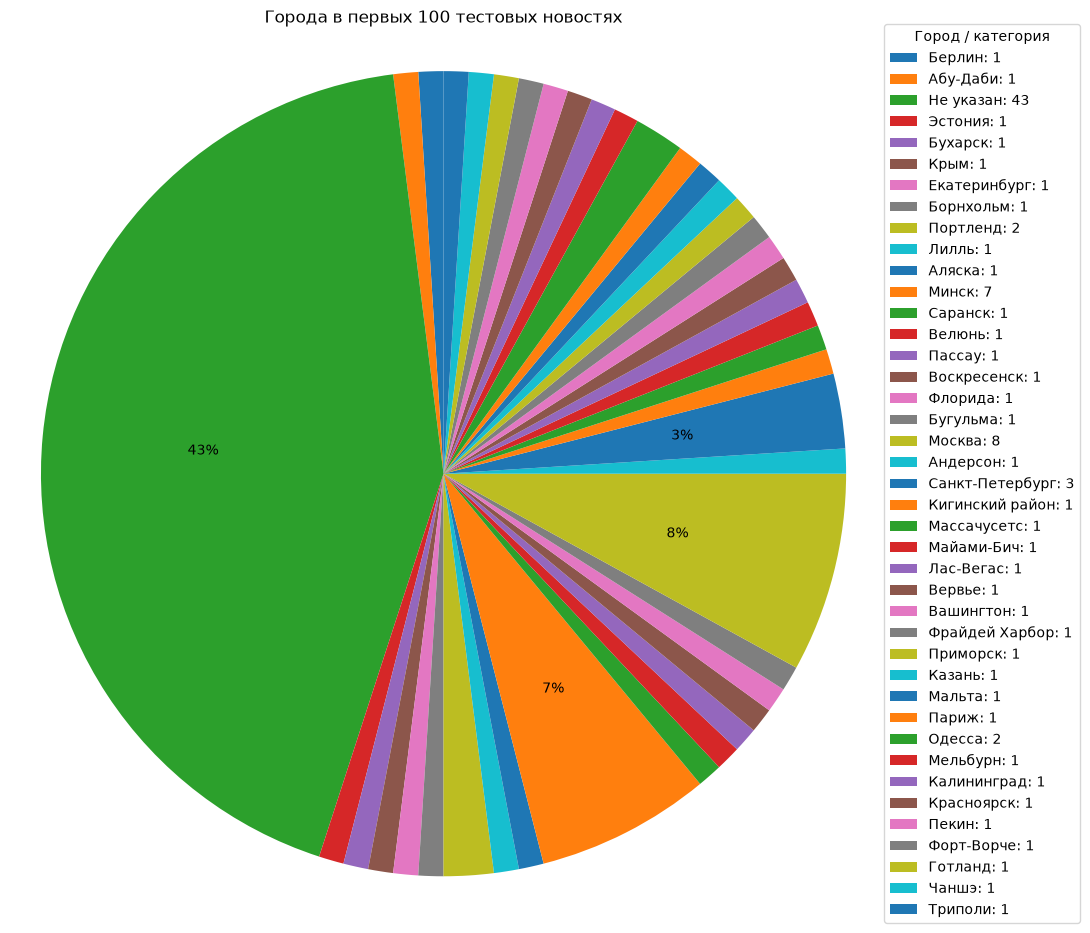

In [8]:
city_results = []
for index, item in enumerate(tqdm(evaluation_news, desc="Города", mininterval=10), 1):
    city_prompt = f"""Прочитай новость и верни только JSON с одним полем city.
city: город основного события, явно названный в новости, в именительном падеже на русском языке.
Если городов несколько, выбери город основного события. Если город не указан, верни null.
Не определяй город по стране или другим косвенным признакам. Не добавляй пояснений.

Новость:
{item['text'][:TEXT_CHAR_LIMIT]}

JSON:"""
    answer = ask_llm(city_prompt)
    try:
        city = json.loads(answer)["city"]
        if city is None or (isinstance(city, str) and not city.strip()):
            category = "Не указан"
        elif isinstance(city, str):
            category = city.strip()
        else:
            category = "Ошибка JSON"
    except (json.JSONDecodeError, KeyError, TypeError):
        category = "Ошибка JSON"
    city_results.append({"index": index, "city": category, "answer": answer})

city_counts = Counter(item["city"] for item in city_results)
print("Обработано новостей:", sum(city_counts.values()))
print(city_counts)

fig, ax = plt.subplots(figsize=(11, max(7, len(city_counts) * 0.25)))
wedges, _, _ = ax.pie(
    city_counts.values(), startangle=90,
    autopct=lambda value: f"{value:.0f}%" if value >= 3 else "",
)
ax.legend(
    wedges, [f"{city}: {count}" for city, count in city_counts.items()],
    title="Город / категория", loc="center left", bbox_to_anchor=(1, 0.5),
)
ax.set_title("Города в первых 100 тестовых новостях")
ax.axis("equal")
plt.tight_layout()
plt.show()

## 2. Как оценить резюме?

В разделе 1 мы сравнивали ответы модели с эталоном на глаз. На одной новости это возможно, но на сотне уже нет. Эталонное резюме позволяет сравнивать ответы автоматически: метрика сопоставляет текст модели с текстом эталона и возвращает число от 0 до 1. Чем оно больше, тем больше слов и словосочетаний у ответа совпадает с эталоном.

### Как считаются метрики

Все метрики работают со списками слов: текст предварительно приводится к нижнему регистру и разбивается на слова. Последовательность из $n$ подряд идущих слов называется **n-граммой**: 1-грамма - это слово, 2-грамма - пара соседних слов.

**ROUGE-N** сравнивает n-граммы ответа и эталона. Считаются две доли:

$$
\text{Precision} = \frac{\text{число совпавших n-грамм}}{\text{число n-грамм в ответе}}, \qquad
\text{Recall} = \frac{\text{число совпавших n-грамм}}{\text{число n-грамм в эталоне}}
$$

Precision показывает, какая доля ответа есть в эталоне, а recall - какая доля эталона нашлась в ответе. В качестве итога берется их среднее гармоническое, $F = \frac{2PR}{P+R}$. В ноутбуке используется именно оно (`fmeasure`).

- **ROUGE-1** считает совпадения отдельных слов, **ROUGE-2** - пар соседних слов.
- **ROUGE-L** вместо n-грамм ищет **наибольшую общую подпоследовательность** (longest common subsequence, LCS): слова эталона, которые встречаются в ответе в том же порядке, но не обязательно подряд. Precision и recall считаются так же, как выше, только вместо числа совпавших n-грамм берется длина LCS.

**BLEU** изначально создавался для машинного перевода и устроен иначе: он оценивает только долю ответа, которая есть в эталоне (precision). Для $n$ от 1 до 4 считается доля n-грамм ответа, найденных в эталоне, затем эти четыре доли усредняются (геометрическое среднее). Слишком короткие ответы штрафуются отдельным множителем (brevity penalty): иначе ответ из одного удачного слова получал бы высокую оценку. На коротких текстах у ответа часто нет ни одной совпавшей 4-граммы, и BLEU обращается в ноль. Чтобы этого не происходило, в коде используется сглаживание `SmoothingFunction().method1`, которое подставляет вместо нуля очень малое число.

### Пример

Пусть эталон - «Кот сидит на окне», а ответ - «Кот лежит на окне».

| Метрика | Что совпало | Значение |
|---|---|---|
| ROUGE-1 | слова «кот», «на», «окне»: 3 из 4 | 0,75 |
| ROUGE-2 | пара «на окне»: 1 из 3 | 0,33 |
| ROUGE-L | подпоследовательность «кот … на окне»: длина 3 из 4 | 0,75 |

Замена одного слова оставила ROUGE-1 и ROUGE-L высокими, а ROUGE-2 снизила сильнее: одна замена разрушила две соседние пары слов. Эту разницу полезно держать в голове при чтении результатов.


In [9]:
def tokenize(text: str) -> list[str]:
    """Разбивает текст на слова с поддержкой кириллицы.

    Args:
        text: Исходный текст.

    Returns:
        Список слов в нижнем регистре.
    """
    return re.findall(r"\w+", text.lower())

class RussianTokenizer:
    """Токенизатор русского текста для ROUGE."""

    def tokenize(self, text: str) -> list[str]:
        """Разбивает текст на слова.

        Args:
            text: Исходный текст.

        Returns:
            Список слов в нижнем регистре.
        """
        return tokenize(text)

rouge = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], tokenizer=RussianTokenizer())

def score_summary(reference: str, answer: str) -> dict[str, float]:
    """Сравнивает ответ модели с эталонным резюме.

    Args:
        reference: Эталонное резюме.
        answer: Ответ модели.

    Returns:
        Значения BLEU и ROUGE для одной новости.
    """
    reference_tokens, answer_tokens = tokenize(reference), tokenize(answer)
    bleu = sentence_bleu([reference_tokens], answer_tokens, smoothing_function=SmoothingFunction().method1) if answer_tokens else 0.0
    scores = rouge.score(reference, answer)
    return {"bleu": bleu, **{name: score.fmeasure for name, score in scores.items()}}

print("Проверка одинаковых текстов:", score_summary("Кот сидит на окне", "Кот сидит на окне"))
print("Эталон:", row["summary"])
print("Ответ:", prediction)
print("Метрики:", score_summary(row["summary"], prediction))

Проверка одинаковых текстов: {'bleu': 1.0, 'rouge1': 1.0, 'rouge2': 1.0, 'rougeL': 1.0}
Эталон: Протестующие против антикоронавирусных мер немцы скандировали имя российского президента, потому что уважают его. Такое мнение выразил депутат городской палаты представителей Гуннар Линдеманн. На этих выходных в Берлине прошли крупные акции протеста. Манифестанты требовали отменить ношение масок и отказаться от соблюдения безопасного расстояния в 1,5 м друг от друга.
Ответ: В Берлине прошли массовые акции протеста против антикоронавирусных ограничений, в ходе которых участники скандировали имя российского президента. Полиция отреагировала на столкновения, но не сообщила о серьезных инцидентах.
Метрики: {'bleu': 0.07063972392934394, 'rouge1': 0.34210526315789475, 'rouge2': 0.1891891891891892, 'rougeL': 0.18421052631578946}


## 3. Примеры внутри prompt

В разделах 1 и 2 мы описывали задачу только словами: роль, длину, формат. Но не все удается объяснить инструкцией. Например, как именно должно выглядеть «нейтральное резюме в 1–2 предложениях», проще показать на образце. Для этого в prompt добавляют **примеры**: готовые пары «новость → резюме», которые модель видит перед оцениваемой новостью и использует как образец. Веса модели при этом не меняются: примеры существуют только внутри запроса и «забываются» после ответа.

По числу примеров различают три режима:

- **zero-shot** - примеров нет, только инструкция (так мы работали до сих пор);
- **one-shot** - один пример;
- **few-shot** - несколько примеров. В работе берем три.

У примеров есть цена. Каждый из них удлиняет prompt: он занимает место в контекстном окне модели (`n_ctx`), а обработка длинного запроса требует больше времени. Поэтому число примеров нужно выбирать, а не увеличивать без ограничений: более длинный prompt не обязательно дает лучший результат.

### Откуда берутся примеры

Примеры берем из части `train`, а оцениваем на части `test`. Если пример окажется той же новостью, которую мы оцениваем, модель получит правильный ответ прямо в запросе, и метрика станет завышенной. Разделение частей исключает такую утечку.

Тексты примеров обрезаются до `EXAMPLE_CHAR_LIMIT` символов, чтобы уменьшить prompt. Обрезка может убрать из статьи информацию, которая упомянута в ее резюме, и тогда пример научит модель «знать» факты, которых нет в тексте. Кроме того, мы берем первые три записи из `train` без отбора, а результат зависит от выбора примеров. Для полноценного эксперимента качество выбранных пар стоит проверять отдельно.

### Шаблон prompt

Prompt собирается функцией `make_template(shot_count)`: инструкция, затем `shot_count` примеров, затем место для оцениваемой новости. На место новости ставится метка `{{news}}`, вместо которой перед запросом подставляется текст статьи. Такой шаблон - отдельный объект: его можно сохранить, сравнить с другим и вернуться к нему. Этим мы воспользуемся в разделе 4, где сравним варианты prompt в MLflow.


In [10]:
def make_template(shot_count: int) -> str:
    """Создает шаблон prompt с заданным числом примеров.

    Args:
        shot_count: Число примеров из обучающей выборки.

    Returns:
        Шаблон MLflow с переменной news.
    """
    parts = ["Ты редактор новостей. Сделай нейтральное резюме в 1–2 предложениях. Не добавляй фактов."]
    for index, item in enumerate(examples[:shot_count], 1):
        example_text = item["text"][:EXAMPLE_CHAR_LIMIT].replace("{{", "{ {").replace("}}", "} }")
        example_summary = item["summary"].replace("{{", "{ {").replace("}}", "} }")
        parts.append(f"Пример {index}:\nНовость: {example_text}\nРезюме: {example_summary}")
    parts.append("Новость:\n{{news}}\n\nРезюме:")
    return "\n\n".join(parts)

one_shot_template = make_template(1)
one_shot_prompt = one_shot_template.replace("{{news}}", news)
one_shot_prediction = ask_llm(one_shot_prompt)
print("One-shot:\n", one_shot_prediction)

One-shot:
 В Берлине прошли массовые протесты против антиковидных ограничений, в ходе которых участники скандировали имя российского президента, а в некоторых районах произошли столкновения с полицией. Правительство подчеркивает, что протесты были мирными, но в некоторых местах наблюдалось насилие.


In [11]:
few_shot_template = make_template(3)
few_shot_prompt = few_shot_template.replace("{{news}}", news)
few_shot_prediction = ask_llm(few_shot_prompt)
print("Few-shot:\n", few_shot_prediction)

Few-shot:
 В Берлине прошли массовые протесты против антиковидных ограничений, в ходе которых участники скандировали имя российского президента, а в некоторых районах произошли столкновения с полицией. Марш проходил в основном мирно, но в районе российского посольства были случаи напряженности.


## 4. Сравнение prompt и эксперимент в MLflow

В разделе 3 мы сравнивали zero-shot, one-shot и few-shot на одной новости, и по одному примеру нельзя судить о качестве варианта. Теперь сравним варианты prompt на большой выборке и сохраним результаты так, чтобы любой эксперимент можно было повторить.

Prompt - такая же часть эксперимента, как модель и данные. Если изменить в нем одну фразу, метрики изменятся, и без записи прежнего текста узнать, какой prompt дал какой результат, невозможно. Поэтому каждый вариант prompt сохраняется вместе с результатами запуска.

### Что делаем в разделе

1. **Настройте MLflow.** Запустите готовую ячейку с tracking URI и названием эксперимента.
2. **Выполните задание.** Самостоятельно организуйте оценку вариантов prompt: для каждой новости сгенерируйте резюме, измерьте время и посчитайте BLEU и ROUGE. Проведите эксперимент для нескольких значений количества примеров, например 0, 1, 5 и 10. Сохраните в MLflow параметры, prompt, данные, средние метрики.
3. **Постройте график.** Самостоятельно постройте график зависимости BLEU и ROUGE-L от количества примеров в prompt. Отдельно сравните длину prompt и время генерации.
4. **Выберите лучший вариант.** Объясните, какой prompt оказался лучшим и какие компромиссы появились между качеством, длиной запроса и временем работы.



In [12]:
from mlflow.tracking import MlflowClient

mlflow.set_tracking_uri(f"sqlite:///{CACHE_DIR / 'mlflow.db'}")
client = MlflowClient()
if client.get_experiment_by_name("pz3_prompt_research") is None:
    client.create_experiment(
        "pz3_prompt_research", artifact_location=(CACHE_DIR / "mlruns").as_uri(),
    )
mlflow.set_experiment("pz3_prompt_research")

print("MLflow настроен. Prompt будут сравниваться в отдельных запусках.")

2026/10/31 18:40:13 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/10/31 18:40:13 INFO mlflow.store.db.utils: Updating database tables


MLflow настроен. Prompt будут сравниваться в отдельных запусках.


In [13]:
shot_counts = [0, 1, 5, 10]
experiment_results = []

for shot_count in shot_counts:
    template = make_template(shot_count)
    with mlflow.start_run(run_name=f"{shot_count}-shot"):
        mlflow.log_params({
            "model_repo": MODEL_REPO, "model_filename": MODEL_FILENAME,
            "seed": SEED, "shot_count": shot_count, "n_eval": len(evaluation_news),
            "text_char_limit": TEXT_CHAR_LIMIT, "example_char_limit": EXAMPLE_CHAR_LIMIT,
            "max_tokens": MAX_TOKENS, "temperature": 0.0, "n_ctx": 8192,
        })
        mlflow.log_text(template, "prompt.txt")
        mlflow.log_dict({
            "evaluation_news": evaluation_news,
            "examples": examples[:shot_count],
        }, "data.json")
        predictions = []
        for index, item in enumerate(tqdm(
            evaluation_news, desc=f"{shot_count}-shot", mininterval=10,
        ), 1):
            prompt = template.replace("{{news}}", item["text"][:TEXT_CHAR_LIMIT])
            started = time.perf_counter()
            answer = ask_llm(prompt)
            seconds = time.perf_counter() - started
            predictions.append({
                "index": index, "reference": item["summary"], "answer": answer,
                "prompt_chars": len(prompt), "seconds": seconds,
                **score_summary(item["summary"], answer),
            })
        prediction_table = pd.DataFrame(predictions)
        metrics = prediction_table[["bleu", "rouge1", "rouge2", "rougeL"]].mean().to_dict()
        metrics["mean_seconds"] = float(prediction_table["seconds"].mean())
        metrics["mean_prompt_chars"] = float(prediction_table["prompt_chars"].mean())
        mlflow.log_metrics(metrics)
        mlflow.log_dict(predictions, "predictions.json")
        experiment_results.append({"shot_count": shot_count, **metrics})
        print(f"{shot_count}-shot: ROUGE-L={metrics['rougeL']:.4f}, "
              f"BLEU={metrics['bleu']:.4f}, время={metrics['mean_seconds']:.2f} с")

results = pd.DataFrame(experiment_results)
display(results.round(4))
best = results.sort_values(["rougeL", "mean_seconds"], ascending=[False, True]).iloc[0]
print(f"Лучший вариант по ROUGE-L: {int(best['shot_count'])}-shot "
      f"(ROUGE-L={best['rougeL']:.4f}, BLEU={best['bleu']:.4f}).")

0-shot:   0%|          | 0/100 [00:00<?, ?it/s]

0-shot:   3%|▎         | 3/100 [00:14<07:41,  4.76s/it]

0-shot:   3%|▎         | 3/100 [00:24<07:41,  4.76s/it]

0-shot:   6%|▌         | 6/100 [00:30<08:10,  5.22s/it]

0-shot:   6%|▌         | 6/100 [00:41<08:10,  5.22s/it]

...

10-shot:  99%|█████████▉| 99/100 [10:28<00:06,  6.35s/it]

10-shot: 100%|██████████| 100/100 [10:35<00:00,  6.36s/it]

10-shot: ROUGE-L=0.1875, BLEU=0.0532, время=6.36 с


,shot_count,bleu,rouge1,rouge2,rougeL,mean_seconds,mean_prompt_chars
0,0,0.0405,0.2393,0.0802,0.1770,5.1301,3103.69
1,1,0.0397,0.2395,0.0746,0.1746,5.4061,4133.69
2,5,0.0475,0.2541,0.0869,0.1903,5.9980,8092.69
3,10,0.0532,0.2604,0.0955,0.1875,6.3569,12751.69


Лучший вариант по ROUGE-L: 5-shot (ROUGE-L=0.1903, BLEU=0.0475).


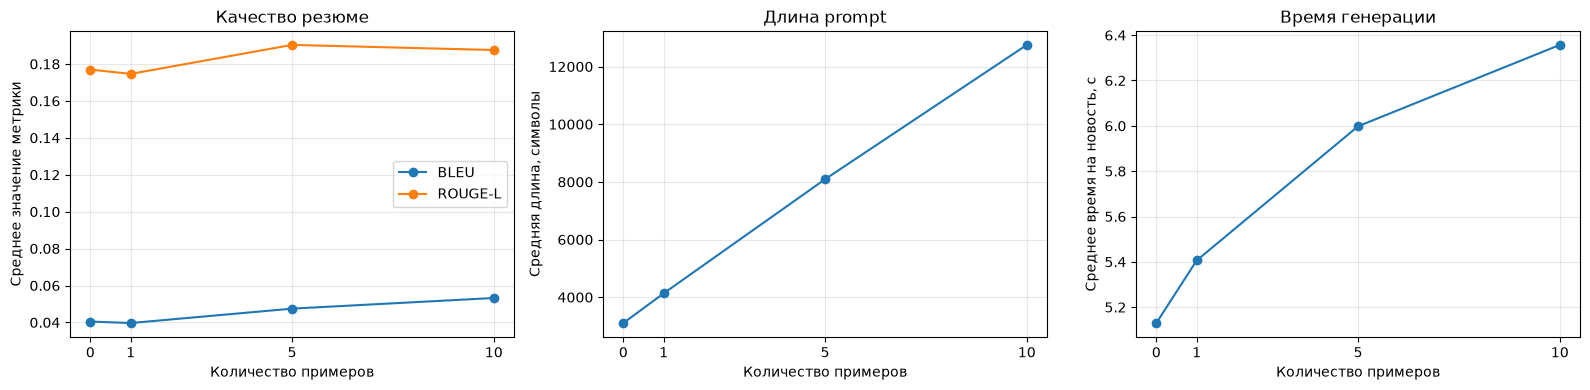

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(results["shot_count"], results["bleu"], marker="o", label="BLEU")
axes[0].plot(results["shot_count"], results["rougeL"], marker="o", label="ROUGE-L")
axes[0].set_title("Качество резюме")
axes[0].set_ylabel("Среднее значение метрики")
axes[0].legend()
axes[1].plot(results["shot_count"], results["mean_prompt_chars"], marker="o")
axes[1].set_title("Длина prompt")
axes[1].set_ylabel("Средняя длина, символы")
axes[2].plot(results["shot_count"], results["mean_seconds"], marker="o")
axes[2].set_title("Время генерации")
axes[2].set_ylabel("Среднее время на новость, с")
for ax in axes:
    ax.set_xlabel("Количество примеров")
    ax.set_xticks(shot_counts)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Почему значения получаются низкими

Особенно это заметно для BLEU. Он создавался для перевода, где у фразы мало допустимых вариантов. Резюме же одну и ту же мысль можно написать многими способами, и длинные совпадающие цепочки слов встречаются редко. Поэтому абсолютное значение BLEU для резюме обычно низкое и не означает, что модель справляется плохо.

Для ориентира: в статье, где представлен корпус Gazeta, модель mBART, дообученная на этих данных, получает ROUGE-1 около 0,32, ROUGE-2 около 0,14 и ROUGE-L около 0,28 (в статье значения даны в процентах, здесь пересчитаны в доли). Результаты готовой модели с инструкцией оказываются того же порядка. Прямое сравнение неточно: реализации метрик, токенизация и выборка новостей могут отличаться.

### Выводы

В задании 1 обработаны 100 новостей, все ответы разобраны как JSON. В 43 ответах город не указан. Чаще всего модель назвала Москву (8), Минск (7) и Санкт-Петербург (3). Среди ответов встречаются страны и регионы, например «Эстония» и «Крым»: корректный JSON не гарантирует правильное извлечение города.

По среднему ROUGE-L выбран вариант с пятью примерами: ROUGE-L = 0,1903, BLEU = 0,0475. Без примеров ROUGE-L = 0,1770, BLEU = 0,0405. Улучшение потребовало увеличения средней длины prompt с 3104 до 8093 символов и времени генерации с 5,13 до 6,00 с на новость.

Десять примеров дали наибольший BLEU (0,0532), но ROUGE-L снизился до 0,1875. При этом средняя длина prompt выросла до 12752 символов, а время — до 6,36 с. Поэтому больше примеров не означает улучшение всех метрик. Вывод относится к этим 100 новостям, выбранной модели и параметрам шаблона.
